### Overview of MPRA Collection

folder of datasets: `/projects/bjgn/jhu30/MPRACollection_data/reviewed`

**How this notebook works**

- Metadata (species, cell line, sequence length range) is read directly from the YAML files. The regulatory element
  type of each study is read from the hand-curated table `res/collection_stat/data/study_meta_revised.csv`.
- Sequence counts need every `X` column of all 276 tables (about 7 GB compressed). These counts are computed once by
  `scripts/compute_collection_stats.py` and saved as small CSV files in `res/collection_stat/data/`. Rerun that script after the
  dataset folder changes (it takes about 15 minutes with 4 workers and needs about 10 GB of memory):

  ```
  python scripts/compute_collection_stats.py --n-workers 4
  ```
- A "unique sequence" is a distinct string in the `X` column, as in the `number of unique_inputs` field of the YAML
  files (a sequence and its reverse complement count as two).
- Figures are saved as PDF and PNG files in `res/collection_stat/plots/`.

In [ ]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
import yaml

DATA_DIR = Path("/projects/bjgn/jhu30/MPRACollection_data/reviewed")
RES_DIR = Path("../res/collection_stat")  # paths are relative to figures/, where this notebook runs
STATS_DIR = RES_DIR / "data"  # output of scripts/compute_collection_stats.py
PLOT_DIR = RES_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

PALETTE = sns.color_palette("muted")
INK, INK_2, INK_3, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df"

plt.rcParams.update({
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
    # "axes.labelcolor": INK_2, "axes.edgecolor": INK_3, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "figure.dpi": 120
})


def save(fig, name):
    fig.savefig(PLOT_DIR / f"{name}.pdf", dpi=300, bbox_inches='tight')


def fmt_count(n):
    """1234567 -> '1.2M'."""
    for div, unit in ((1e9, "B"), (1e6, "M"), (1e3, "k")):
        if n >= div:
            return f"{n / div:.1f}{unit}".replace(".0" + unit, unit)
    return f"{int(n)}"


def log_axis(ax, axis="x"):
    """Log axis with ticks at powers of ten labeled 10, 1k, 1M, ..."""
    getattr(ax, f"set_{axis}scale")("log")
    a = ax.xaxis if axis == "x" else ax.yaxis
    a.set_major_locator(mticker.LogLocator(base=10, numticks=12))
    a.set_major_formatter(mticker.FuncFormatter(lambda v, _: fmt_count(v)))
    a.set_minor_locator(mticker.LogLocator(base=10, subs=np.arange(2, 10), numticks=12))
    a.set_minor_formatter(mticker.NullFormatter())

#### Load study and table metadata
A metadata field can be set for the whole study (`Shared Metadata` in `study.yaml`) or for one table
(`Table Metadata` in `<table>.yaml`); the table value takes precedence. Some fields map each `Y` column to its own value
(for example one cell line per `Y` column), so every field is read as a list of values.

In [8]:
def load_yaml(path):
    with open(path) as f:
        return yaml.safe_load(f) or {}


studies = sorted(p.name for p in DATA_DIR.iterdir() if (p / "study.yaml").exists())
study_meta = {s: load_yaml(DATA_DIR / s / "study.yaml") for s in studies}
table_meta = {
    (s, f.stem): load_yaml(f) for s in studies for f in sorted((DATA_DIR / s).glob("*.yaml")) if f.name != "study.yaml"
}


def as_list(value):
    """Return a metadata value as a list of strings."""
    if value is None:
        return []
    if isinstance(value, dict):
        if "Name" in value:  # e.g. {'Name': ..., 'Source Details': ...}
            return [str(value["Name"])]
        return [v for x in value.values() for v in as_list(x)]
    if isinstance(value, list):
        return [v for x in value for v in as_list(x)]
    return [str(value)]


def table_field(study, table, key):
    """Value of a metadata field for one table: the table value, otherwise the study value."""
    tm = table_meta[(study, table)].get("Table Metadata") or {}
    if key in tm:
        return as_list(tm[key])
    return as_list((study_meta[study].get("Shared Metadata") or {}).get(key))


def study_field(study, key):
    """All distinct values of a metadata field over the tables of a study."""
    return sorted({v for (s, t) in table_meta if s == study for v in table_field(s, t, key)})


def study_label(study):
    """'NatureGenetics_2022_DeAlmeida' -> 'DeAlmeida 2022'."""
    journal, year, author = study.split("_", 2)
    return f"{author} {year}"


meta = pd.DataFrame({
    "study": studies,
    "journal": [s.split("_", 2)[0] for s in studies],
    "year": [int(s.split("_", 2)[1]) for s in studies],
    "label": [study_label(s) for s in studies],
    "n_tables": [sum(s == k[0] for k in table_meta) for s in studies],
}).set_index("study")
print(f"{len(studies)} studies, {len(table_meta)} tables")

42 studies, 273 tables


#### Regulatory element categories
Regulatory element labels read from `res/collection_stat/data/study_meta_revised.csv` (column `element`). `CRE` (cis-regulatory element) groups studies of
candidate regulatory regions that are not restricted to one element type, including libraries of windows centered on
eQTL or GWAS variants. `Unconstrained` groups studies whose regions were not selected for regulatory function. The
free-text `Regulatory Element` field of the YAML files is shown as `element_raw` for comparison.

In [9]:
RE_ORDER = ["Enhancer", "CRE", "Promoter + enhancer", "Promoter", "5' UTR", "3' UTR", "Splicing / intron", "Unconstrained"]
RE_COLORS = dict(zip(RE_ORDER, PALETTE))
ELEMENT_FILE = STATS_DIR / "study_meta_revised.csv"

# match labels without regard to case, so that 'unconstrained' in the file becomes 'Unconstrained'
element_map = pd.read_csv(ELEMENT_FILE, index_col="study")["element"].str.lower().map({c.lower(): c for c in RE_ORDER})
missing = sorted(set(studies) - set(element_map.index))
unknown = element_map[element_map.isna()]
assert not missing, f"studies missing from {ELEMENT_FILE}: {missing}"
assert unknown.empty, f"element labels not in RE_ORDER: {list(unknown.index)}"

meta["element"] = element_map.reindex(meta.index)
meta["element_raw"] = [" | ".join(study_field(s, "Regulatory Element")) for s in studies]
with pd.option_context("display.max_colwidth", 90, "display.max_rows", 100):
    display(meta.assign(_g=meta["element"].map(RE_ORDER.index)).sort_values("_g")[["element", "element_raw"]])

,element,element_raw
study,,
CellSystems_2020_Davis,Enhancer,Enhancer (synthetic CRE architectures upstream of a minimal promoter)
CellSystems_2025_Yin,Enhancer,Enhancer
Cell_2025_Frömel,Enhancer,Enhancer (element upstream of a minimal promoter)
GenomeBiology_2026_Rühle,Enhancer,Enhancer
GenomeResearch_2013_Kheradpour,Enhancer,Enhancer
NatureBiotechnology_2012_Melnikov,Enhancer,Enhancer
NatureGenetics_2022_DeAlmeida,Enhancer,Enhancer
NatureCommunications_2023_Georgakopoulos-Soares,Enhancer,Enhancer (synthetic: TF binding sites placed in two neutral genomic backgrounds; nativ...
NatureMethods_2020_Klein,Enhancer,Enhancer (HepG2 candidate enhancers from FOXA1 / FOXA2 / HNF4A ChIP-seq peaks of Inoue...


Fig1 - distribution of regulatory element types. Piechart of number of studies focusing on different types of regulatory elements (the element type of each study is read from `res/collection_stat/data/study_meta_revised.csv`)

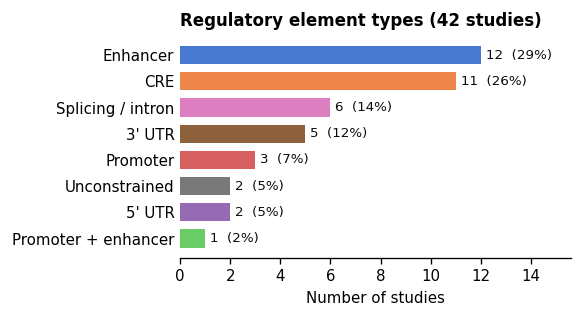

In [10]:
counts = meta["element"].value_counts().reindex(RE_ORDER).fillna(0).astype(int).sort_values()

fig, ax = plt.subplots(figsize=(4.2, 2.4))
bars = ax.barh(counts.index, counts.values, color=[RE_COLORS[c] for c in counts.index], height=0.7)
ax.bar_label(bars, labels=[f"{n}  ({n / counts.sum():.0%})" for n in counts], padding=3, color=INK, fontsize=8)
ax.set_xlabel("Number of studies")
ax.set_xlim(0, counts.max() * 1.3)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title(f"Regulatory element types ({counts.sum()} studies)")
save(fig, "fig1_regulatory_elements")

*Format:* a sorted bar chart instead of a pie chart. Several categories hold only one or two studies; bar lengths make
these small counts easy to compare, while thin pie slices do not.

#### Load the sequence counts computed by `compute_collection_stats.py`
The per-study counts are checked against `number of unique_inputs` in each `study.yaml`.

In [6]:
study_stats = pd.read_csv(STATS_DIR / "study_stats.csv").set_index("study")
origin_counts = pd.read_csv(STATS_DIR / "study_origin_counts.csv")
global_origin = pd.read_csv(STATS_DIR / "global_origin_counts.csv")

meta = meta.join(study_stats.drop(columns="n_tables"))
meta["n_unique_yaml"] = [study_meta[s].get("number of unique_inputs") for s in studies]
mismatch = meta[meta["n_unique"] != meta["n_unique_yaml"]]
print(f"Studies whose computed count differs from study.yaml: {len(mismatch)}")
display(mismatch[["n_unique", "n_unique_yaml"]])
print(f"Rows: {meta['n_rows'].sum():,};  unique sequences summed over studies: {meta['n_unique'].sum():,}")

Studies whose computed count differs from study.yaml: 1


,n_unique,n_unique_yaml
study,,
NatureGenetics_2022_Sahu,18242083,18842801


Rows: 172,673,231;  unique sequences summed over studies: 160,279,055


Fig2 - distribution of sequence types. Piechart of total number of unique sequences for each sequence type. This can be retrieved through computing the number of sequences with different types of 'obs_X: sequence origin'. Count only sequences with obs_X: control role=test

                n_unique_test  n_unique_test_summed_over_studies  n_studies
origin                                                                     
model_designed       136244.0                           187524.0       13.0
perturbed            269134.0                           275846.0       20.0
synthetic            396170.0                           402376.0       16.0
variant              939357.0                           942318.0       13.0
native             18184718.0                         18189500.0       33.0
random            130137552.0                        140080467.0       11.0


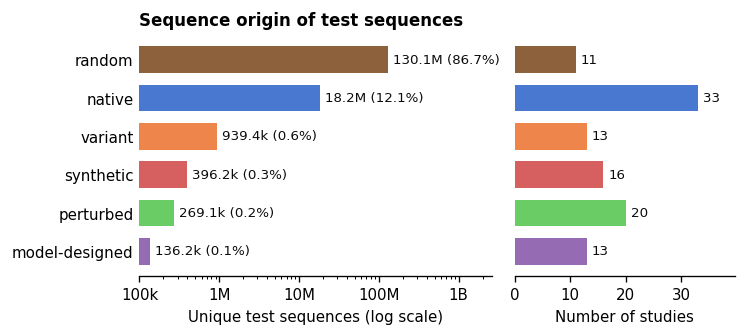

In [7]:
ORIGIN_ORDER = ["native", "variant", "perturbed", "synthetic", "model_designed", "random", "shuffled"]
ORIGIN_COLORS = dict(zip(ORIGIN_ORDER, PALETTE))
ORIGIN_LABELS = {o: o.replace("_", "-") for o in ORIGIN_ORDER}

g = global_origin.set_index("origin").reindex(ORIGIN_ORDER).dropna(subset=["n_unique_test"])
g = g.sort_values("n_unique_test")
print(g)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.4, 2.6), sharey=True, gridspec_kw=dict(width_ratios=[1.6, 1], wspace=0.08))
colors = [ORIGIN_COLORS[o] for o in g.index]
labels = [ORIGIN_LABELS[o] for o in g.index]

bars = ax1.barh(labels, g["n_unique_test"], color=colors, height=0.7)
log_axis(ax1, "x")
ax1.set_xlim(10 ** np.floor(np.log10(g["n_unique_test"].min())), g["n_unique_test"].max() * 20)
total = g["n_unique_test"].sum()
ax1.bar_label(bars, labels=[f"{fmt_count(n)} ({n / total:.1%})" for n in g["n_unique_test"]], padding=3, color=INK, fontsize=8)
ax1.set_xlabel("Unique test sequences (log scale)")
ax1.set_title("Sequence origin of test sequences")

bars = ax2.barh(labels, g["n_studies"], color=colors, height=0.7)
ax2.bar_label(bars, padding=3, color=INK, fontsize=8)
ax2.set_xlim(0, g["n_studies"].max() * 1.2)
ax2.set_xlabel("Number of studies")
for ax in (ax1, ax2):
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
save(fig, "fig2_sequence_origin")

*Format:* bar charts on a log scale instead of a pie chart. Random sequences from a few very large libraries (de Boer
2020, Vaishnav 2022, Sahu 2022) make up most of the total, so in a pie chart every other category would be a sliver.
The right panel shows how many studies contribute each origin, which the sequence totals hide.

*Counting:* only rows with `obs_X: control role = test` are counted. A sequence is counted once even if it appears in
several tables or studies. A sequence that carries two different origin labels is counted under both.

Fig3 - distribution of number of sequences per study. Horizontal swarmplot showing the total number of unique sequences per study (each dot represents a study), likely need to be on log scale.

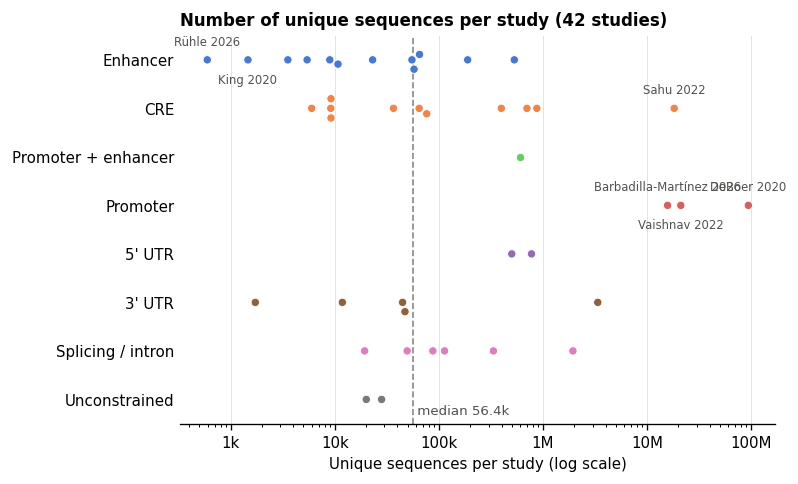

In [8]:
df = meta.reset_index()
fig, ax = plt.subplots(figsize=(6.4, 4.2))
sns.swarmplot(data=df, x="n_unique", y="element", order=RE_ORDER, hue="element", palette=RE_COLORS,
              log_scale=True, size=5, linewidth=0.5, edgecolor="white", legend=False, ax=ax)
log_axis(ax, "x")
ax.set_xlabel("Unique sequences per study (log scale)")
ax.set_ylabel("")
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.grid(axis="x", color=GRID, linewidth=0.6)
ax.set_axisbelow(True)
median = df["n_unique"].median()
ax.axvline(median, color=INK_3, linewidth=1, linestyle="--")
ax.text(median, len(RE_ORDER) - 0.62, f" median {fmt_count(median)}", color=INK_2, fontsize=8, ha="left", va="bottom")

# name the largest and smallest studies; labels in the same row alternate above and below the points
named = pd.concat([df.nlargest(4, "n_unique"), df.nsmallest(2, "n_unique")]).sort_values("n_unique")
for _, row_df in named.groupby("element"):
    for i, (_, r) in enumerate(row_df.iterrows()):
        above = i % 2 == 0
        ax.annotate(r["label"], (r["n_unique"], RE_ORDER.index(r["element"])), xytext=(0, 7 if above else -8),
                    textcoords="offset points", ha="center", va="bottom" if above else "top", fontsize=7, color=INK_2)
ax.set_title(f"Number of unique sequences per study ({len(df)} studies)")
save(fig, "fig3_sequences_per_study")

*Format:* one swarm row per regulatory element type, so the plot also shows which kinds of studies produce the largest
libraries. The dashed line is the median over all studies.

Fig4 - overview of each study (library size, sequence origin composition, sequence length)

Studies share one vertical axis and are grouped by regulatory element type. This shows what each study contributes, which the
collection-wide totals in Fig 2 hide.

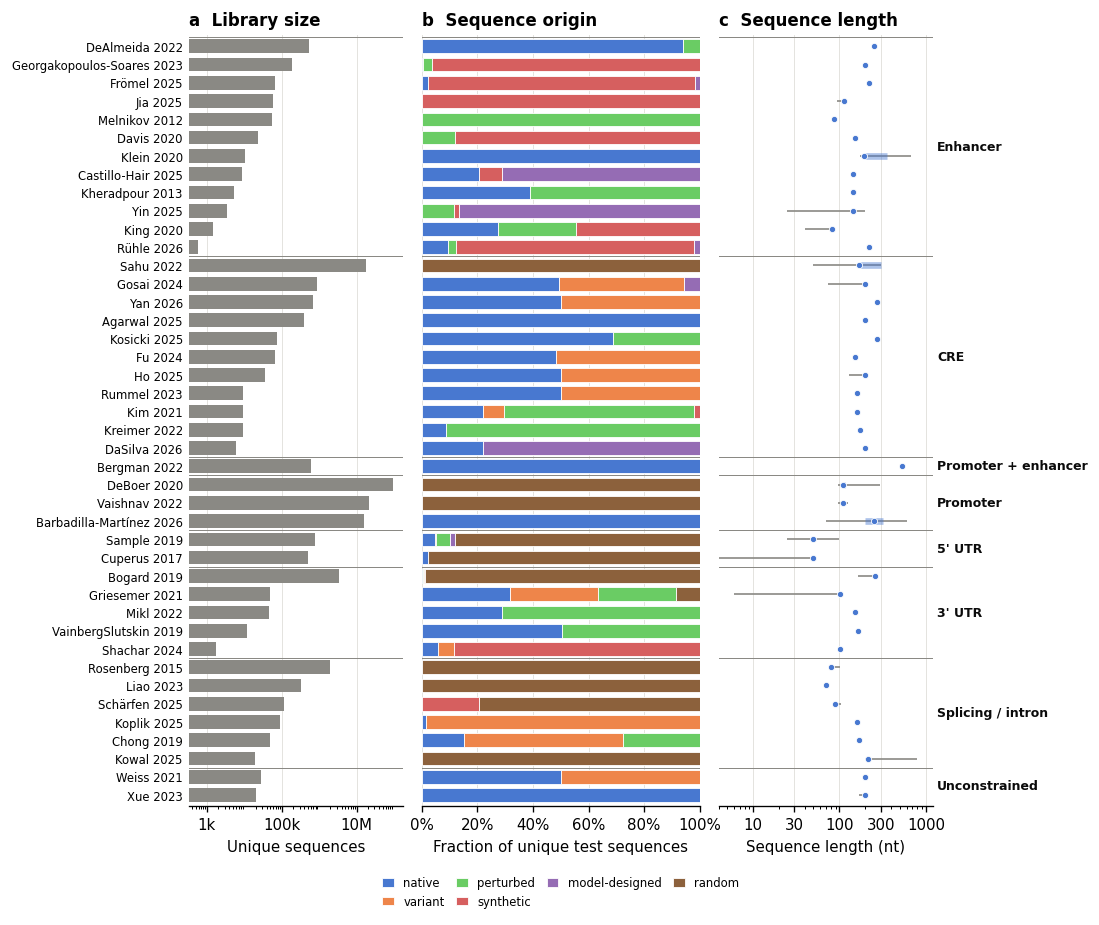

In [9]:
# study order: grouped by regulatory element type, largest library first within each group
order = meta.assign(_g=meta["element"].map(RE_ORDER.index)).sort_values(["_g", "n_unique"], ascending=[True, False]).index
ypos = {s: i for i, s in enumerate(order)}

comp = (origin_counts[origin_counts["role"] == "test"]
        .pivot_table(index="study", columns="origin", values="n_unique", aggfunc="sum", fill_value=0)
        .reindex(index=order, columns=ORIGIN_ORDER, fill_value=0))
comp = comp.div(comp.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(8.0, 0.17 * len(order) + 1.2), sharey=True,
                                    gridspec_kw=dict(width_ratios=[1, 1.3, 1], wspace=0.08))
y = np.arange(len(order))

# (a) library size
# neutral bars: in this figure, color encodes sequence origin only (panel b)
ax1.barh(y, meta.loc[order, "n_unique"], color=INK_3, height=0.75)
log_axis(ax1, "x")
ax1.set_xticks([1e3, 1e5, 1e7])
ax1.set_xlabel("Unique sequences")
ax1.set_title("a  Library size")

# (b) sequence origin composition of test sequences
left = np.zeros(len(order))
for o in [o for o in ORIGIN_ORDER if comp[o].sum() > 0]:
    ax2.barh(y, comp[o], left=left, color=ORIGIN_COLORS[o], height=0.75, edgecolor="white", linewidth=0.5,
             label=ORIGIN_LABELS[o])
    left += comp[o].to_numpy()
ax2.set_xlim(0, 1)
ax2.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax2.set_xlabel("Fraction of unique test sequences")
ax2.set_title("b  Sequence origin")
ax_height_in = ax2.get_position().height * fig.get_figheight()
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.5 / ax_height_in), ncol=4, fontsize=7, handlelength=1,
           columnspacing=1)

# (c) sequence length over unique sequences: thin line = min to max, thick line = 25th to 75th percentile, dot = median
L = meta.loc[order]
ax3.hlines(y, L["len_min"], L["len_max"], color=INK_3, linewidth=1)
ax3.hlines(y, L["len_q25"], L["len_q75"], color=PALETTE[0], linewidth=4, alpha=0.45)
ax3.scatter(L["len_median"], y, color=PALETTE[0], s=14, zorder=3, edgecolor="white", linewidth=0.5)
ax3.set_xscale("log")
ax3.set_xlim(4, 1200)
ax3.xaxis.set_major_formatter(mticker.ScalarFormatter())
ax3.xaxis.set_minor_formatter(mticker.NullFormatter())
ax3.set_xticks([10, 30, 100, 300, 1000])
ax3.set_xlabel("Sequence length (nt)")
ax3.set_title("c  Sequence length")

ax1.set_yticks(y, meta.loc[order, "label"], fontsize=7)
ax1.set_ylim(len(order) - 0.4, -0.6)
for ax in (ax1, ax2, ax3):
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)
    ax.grid(axis="x", color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)

# separators and labels for regulatory element groups
for e in RE_ORDER:
    rows = [ypos[s] for s in order if meta.loc[s, "element"] == e]
    if not rows:
        continue
    for ax in (ax1, ax2, ax3):
        ax.axhline(min(rows) - 0.5, color=INK_3, linewidth=0.6)
    ax3.text(1.02, (min(rows) + max(rows)) / 2, e, transform=ax3.get_yaxis_transform(), va="center", ha="left",
             fontsize=7.5, color=INK, fontweight="bold")
save(fig, "fig4_study_overview")